In [1]:
#Import packages
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
import torch
import transformers as ppb
import warnings
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
import os
import matplotlib.pyplot as plt

c:\Users\s2720\anaconda3\envs\tinyBERT1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#參數設置區

#資料集、模型選擇參數設置區
dataSet = 'Final_XSS_Dataset' #選項有 'XSS_dataset'、'HttpParamsDataset'、'PortSwigger_XSSDataSet'、'XSSed_CSIC2010'、'Final_XSS_Dataset'
modelType = 'tinyBERT' #選項有 'BERT'、'DistilBERT'、'tinyBERT'

#I/O參數設置區

if dataSet == 'XSS_dataset':
  dataSetPath = './TrainingData/DataSet/XSS_dataset.csv'
elif dataSet == 'HttpParamsDataset':
  dataSetPath = './TrainingData/DataSetOfHttpParamsDataset/payload_train.csv'
elif dataSet == 'PortSwigger_XSSDataSet':
  dataSetPath = './TrainingData/Final_PortSwigger_XSSDataset(資料集內容待驗證)/PortSwigger_XSSDataSet.csv'
elif dataSet == 'XSSed_CSIC2010':
  dataSetPath = './TrainingData/Final_XSSed_CSIC2010FromKaggle(資料集內容待驗證)/XSSed_CSIC2010.csv'
elif dataSet == 'Final_XSS_Dataset':
  dataSetPath = './TrainingData/xss_encoded_dataset_train.csv'
elif dataSet == 'XSSDataset_From_BERT_BiLSTM':
  dataSetPath = './TrainingData/XSSDataset_From_BERT_BiLSTM/XSSTraining.csv'

In [3]:
#載入資料集
df = pd.read_csv( dataSetPath, header = None )

In [4]:
#Loading Pre-trained Model

#Loading Pre-trained BERT Model:
if modelType == 'DistilBERT':
  model_class, tokenizer_class, pretrained_weights = ( ppb.DistilBertModel, ppb.DistilBertTokenizer, 'distilbert-base-uncased' )
elif modelType == 'BERT':
  model_class, tokenizer_class, pretrained_weights = ( ppb.BertModel, ppb.BertTokenizer, 'bert-base-uncased' )
elif modelType == 'tinyBERT': #此條件式內部的內容皆為GPT生成的，目前正在測試相關功能
  tokenizer = ppb.BertTokenizer.from_pretrained("prajjwal1/bert-tiny")
  bert_layer = ppb.TFBertModel.from_pretrained( "prajjwal1/bert-tiny", from_pt = True )

# Load pretrained model/tokenizer
if modelType != 'tinyBERT':
    tokenizer = tokenizer_class.from_pretrained( pretrained_weights )
    model = model_class.from_pretrained( pretrained_weights )

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.seq_relationship.bias', 'cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'bert.embeddings.position_ids', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClas

In [5]:
#Debuging Cell (You can use this cell to debug if you encounter any problems in tokenization)

index = 0

for element in df[0]:
    if type( element ) != type( 'str' ):
        print( 'In index ', index, ': The type of element is ', type( element ) )

    index = index + 1

In [6]:
#Tokenization
# tokenized = df[0].apply( ( lambda x: tokenizer.encode( x, add_special_tokens = True ) ) ) #Stable and crediable method
tokenized = df[0].apply( ( lambda x: tokenizer.encode( x, add_special_tokens = True, truncation = True, max_length = 600 ) ) ) # New and unstable method

In [7]:
#Debuging Cell( You can check the data that have been tokenized here. )

#初始化
tokenized_sample = []
counter = 0

#簡單取幾個樣本
for token in tokenized.values:
    if counter < 1:
        tokenized_sample.append( token )
    counter = counter + 1

#padding
padded_sample = []

for index in range( 0, len(tokenized_sample), 1 ):

    print( 'The type of tokenized_sample[index] is: ', type( tokenized_sample[index] ) )
    element = tokenized_sample[index].copy()

    while len(element) <= 600:

        if len(element) < 600:
            element.append(0)
        else:
            padded_sample.append( element )
            break

padded_sample = np.array( padded_sample )

#masking
mask_sample = np.where( padded_sample != 0, 1, 0 )

#Debug
for index in range( 0, len(tokenized_sample), 1 ):
    print( 'The index is ', index + 1 )
    print( 'The data after tokenization :', tokenized_sample[index] )
    print( 'The decode data after tokenization :', tokenizer.decode( tokenized_sample[index] ) )
    print( 'The data after padded:', padded_sample[index] )
    print( 'The masking of this data:', mask_sample[index] )

The type of tokenized_sample[index] is:  <class 'list'>
The index is  1
The data after tokenization : [101, 1026, 2065, 6444, 2063, 5034, 19797, 10085, 1027, 1000, 1026, 17917, 2290, 2006, 11066, 1027, 3332, 1031, 1005, 1032, 1060, 2575, 2487, 2140, 1032, 1060, 26187, 2099, 1032, 1060, 2581, 2549, 1005, 1033, 1006, 1015, 1007, 1028, 1026, 1013, 17917, 2290, 1028, 1000, 1028, 1026, 1013, 2065, 6444, 2063, 1028, 102]
The decode data after tokenization : [CLS] < iframe srcdoc = " < svg onload = window ['\ x61l \ x65r \ x74'] ( 1 ) > < / svg > " > < / iframe > [SEP]
The data after padded: [  101  1026  2065  6444  2063  5034 19797 10085  1027  1000  1026 17917
  2290  2006 11066  1027  3332  1031  1005  1032  1060  2575  2487  2140
  1032  1060 26187  2099  1032  1060  2581  2549  1005  1033  1006  1015
  1007  1028  1026  1013 17917  2290  1028  1000  1028  1026  1013  2065
  6444  2063  1028   102     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0 

In [8]:
#Padding
padded = []
labels = []
index = 0
maxLen = 0

for token in tokenized.values:

  if len( token ) > maxLen:
    maxLen = len( token )

for token in tokenized.values:

  while len( token ) <= maxLen:

    if len( token ) < maxLen:
      token.append( 0 )

    else:
      padded.append( token )

      if dataSet == 'HttpParamsDataset' :
        labels.append( df.loc[ index, 3 ] )

      else:
        labels.append( df.loc[ index, 1 ] )

      break

  index = index + 1

padded = np.array( padded )
print( type( padded ) )
print( 'The maxium length is ', maxLen )

<class 'numpy.ndarray'>
The maxium length is  600


In [9]:
#如果是使用HttpParamsDataset資料集，對資料集的label作一點處理
if dataSet == 'HttpParamsDataset' :
  print( 'The length of labels is ', len(labels) ) #Debug用

  templabels = [] #將label從字串轉換成整數用，具體作法是先從label list中取出一個label，將其轉換成整數後存進此list中。
                  #當所有label都轉成整數並存進此list後會再將label list重新指向此list。

  for index in range( 0, len( labels ), 1 ):

    if labels[index] == 'norm':
      templabels.append( 0 )

    elif labels[index] == 'anom':
      templabels.append( 1 )

  print( 'The length of templabels is ', len(templabels) ) #Debug用
  labels = templabels

In [10]:
#Debug(印label)
positive_sample = 0
negative_sample = 0
for element in labels:
    if element == 0:
        negative_sample = negative_sample + 1
    elif element == 1:
        positive_sample = positive_sample + 1
    else:
        print( 'error!!' )

print( 'The total number of negative samples are: ', negative_sample )
print( 'The total number of positive samples are: ', positive_sample  )

The total number of negative samples are:  314
The total number of positive samples are:  352


In [11]:
#Debug用

#STEP1: 設計此模型的架構(感謝劉睿寬學弟的協助)

# 輸入：token IDs + attention mask
inputs = keras.Input(shape=(None,), dtype="int64", name="input_ids")
attention_mask = keras.Input(shape=(None,), dtype="int64", name="attention_mask")

# BERT 輸出
bert_outputs = bert_layer(inputs, attention_mask=attention_mask)
sequence_output = bert_outputs.last_hidden_state          # [batch, seq_len, hidden]
pooler_output = bert_outputs.pooler_output               # [batch, hidden]

#Nromalization(嘗試功能)
h_0 = sequence_output[:, 1:, :]
# h_0 = sequence_output
h_1 = layers.Dense( 256, activation = 'relu' )( h_0 )
h_2 = layers.BatchNormalization()(h_1)
h_3 = layers.Dense( 256, activation = 'relu' )(h_2)
h_4 = layers.BatchNormalization()(h_3)

# BiLSTM：處理 sequence_output
bilstm_output = layers.Bidirectional(
    layers.LSTM(128, return_sequences=False)
)(h_4)  # [batch, 256]

adjust_bilstm_output = layers.Dense( 768, activation = 'relu' )(bilstm_output)

# 合併 pooler_output 和 BiLSTM 的輸出
merged = layers.Concatenate()([pooler_output, adjust_bilstm_output])  # [batch, hidden + 256]

# 最終分類層
dropout_merged = layers.Dropout( 0.3 )(merged)
outputs = layers.Dense(2, activation='softmax')(dropout_merged)

#STEP2: 把模型給實例化(instantiated)
model = keras.Model(inputs=[inputs, attention_mask], outputs=outputs)
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_ids (InputLayer)         [(None, None)]       0           []                               
                                                                                                  
 attention_mask (InputLayer)    [(None, None)]       0           []                               
                                                                                                  
 tf_bert_model (TFBertModel)    TFBaseModelOutputWi  4385920     ['input_ids[0][0]',              
                                thPoolingAndCrossAt               'attention_mask[0][0]']         
                                tentions(last_hidde                                               
                                n_state=(None, None                                           

In [12]:
#實作 tinyBERT + BiLSTM 模型的函式

def build_model():

    #STEP1: 設計此模型的架構(感謝劉睿寬學弟的協助)

    # 輸入：token IDs + attention mask
    inputs = keras.Input(shape=(None,), dtype="int64", name="input_ids")
    attention_mask = keras.Input(shape=(None,), dtype="int64", name="attention_mask")

    # BERT 輸出
    bert_outputs = bert_layer(inputs, attention_mask=attention_mask)
    sequence_output = bert_outputs.last_hidden_state          # [batch, seq_len, hidden]
    pooler_output = bert_outputs.pooler_output               # [batch, hidden]

    #Nromalization(嘗試功能)
    h_0 = sequence_output[:, 1:, :]
    # h_0 = sequence_output
    h_1 = layers.Dense( 256, activation = 'relu' )( h_0 )
    h_2 = layers.BatchNormalization()(h_1)
    h_3 = layers.Dense( 256, activation = 'relu' )(h_2)
    h_4 = layers.BatchNormalization()(h_3)

    # BiLSTM：處理 sequence_output
    bilstm_output = layers.Bidirectional(
        layers.LSTM(128, return_sequences=False)
    )(h_4)  # [batch, 256]

    adjust_bilstm_output = layers.Dense( 768, activation = 'relu' )(bilstm_output)

    # 合併 pooler_output 和 BiLSTM 的輸出
    merged = layers.Concatenate()([pooler_output, adjust_bilstm_output])  # [batch, hidden + 256]

    # 最終分類層
    dropout_merged = layers.Dropout( 0.3 )(merged)
    outputs = layers.Dense(2, activation='softmax')(dropout_merged)

    #STEP2: 把模型給實例化(instantiated)
    model = keras.Model(inputs=[inputs, attention_mask], outputs=outputs)

    #STEP3: 設置編譯參數並編譯模型

    #設置參數
    optimizer = tf.keras.optimizers.Adam( learning_rate = 0.00002 ) #這裡用的可能不是論文裡用的optimizer
    loss = 'categorical_crossentropy' #這裡用的可能不是論文裡用的loss function，
                                #目前考慮採用的loss function有
                                #  1) 'BinaryCrossentropy'
                                #  2) 'categorical_crossentropy'

    #編譯模型
    model.compile(
        optimizer = optimizer,
        loss = loss,
        metrics = [ 'accuracy', tf.keras.metrics.Recall() ] #這裡用的可能不是論文裡用的metrics
    )

    #列印成功訊息並回傳模型
    print( 'Model build and compile successfully!!' )
    return model

In [13]:
#訓練參數設置(此配置可能跟論文的配置不同)
epoch = 100
batchSize = 32

In [14]:
# K-fold cross validation

data = padded #準備好所有data
cate_labels = np.array( to_categorical( labels ) ) #準備好所有label

k = 5 #進行K折交叉驗證。e.g. K = 5 即為進行 5-fold cross validation、K = 10 即為進行 10-fold cross validation
num_val_samples = len( data ) // k #計算驗證集的樣本數
all_train_acc_mean = []
all_train_recall_mean = []
all_valid_acc = []
all_valid_recall = []

#開始進行 K-fold cross validation
for i in range(k):
    print( 'Processing fold #', i + 1 )

    #準備此回合的訓練資料: 訓練資料來自第i個區塊
    training_data = data[ i * num_val_samples : ( i + 1 ) * num_val_samples ]
    training_labels = cate_labels[ i * num_val_samples : ( i + 1 ) * num_val_samples ]

    #準備此回合的驗證資料: 訓練資料來自第i個區塊
    valid_data = np.concatenate(
        [data[ : i * num_val_samples ],
         data[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    valid_labels = np.concatenate(
        [cate_labels[ : i * num_val_samples ],
         cate_labels[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    #針對這回合的訓練及驗證資料進行masking
    training_attention_mask = np.where( training_data != 0, 1, 0 )
    valid_attention_mask = np.where( valid_data != 0, 1, 0 )

    model = build_model() #重新建構Keras模型(已編譯過)

    #開始進行本回合的訓練

    #設定call back
    callbacksList = [
        #以下這個callback為在每個週期結束後若loss有改善，則把當下的模型給存起來
        #簡單來說這個callback的目的就是希望可以把loss最好的那個週期的模型給存起來
        keras.callbacks.ModelCheckpoint(
            filepath = "BestModel_TinyBERT_BiLSTM_fold_" + str(i+1) + ".keras", #存檔的路徑及檔名
            monitor = "val_loss", #當loss有改善時才會儲存模型，別忘了若寫了這一行程式碼
                              #則一定要在此callback裡面也加上save_best_only = True這一
                              #行程式碼才行
            save_best_only = True,
        )
    ]

    #開始訓練
    print( 'Start training.' )

    #1/K份為訓練資料版( e.g. 1/10為訓練資料版)
    training_history = model.fit(
                           [ training_data, training_attention_mask ], #訓練資料，貌似需為NumPy陣列或DataSet物件
                             training_labels, #訓練資料的label，貌似需為NumPy陣列或DataSet物件
                             epochs = epoch,
                             batch_size = batchSize,
                             callbacks = callbacksList,
                             validation_data=([valid_data, valid_attention_mask], valid_labels)
                       )

    '''
    #(K-1)/K份為訓練資料版( e.g. 9/10為訓練資料版)
    training_history = model.fit(
                           [ valid_data, valid_attention_mask ], #訓練資料，貌似需為NumPy陣列或DataSet物件
                             valid_labels, #訓練資料的label，貌似需為NumPy陣列或DataSet物件
                             epochs = epoch,
                             batch_size = batchSize,
                             callbacks = callbacksList,
                       )
    '''

    #儲存部份訓練資訊
    average_acc_train = np.mean( training_history.history[ 'accuracy' ] )
    all_train_acc_mean.append( average_acc_train )
    print( 'The average acc in training phase is:', average_acc_train  )
    # average_recall_train = np.mean( training_history.history[ 'recall' ] )
    # all_train_recall_mean.append( average_recall_train )
    # print( 'The average recall in training phase is:', average_recall_train  )

    #開始進行本回合的驗證

    #載入表現最佳的模型
    model = keras.models.load_model (
        "BestModel_TinyBERT_BiLSTM_fold_" + str(i+1) + ".keras",
        custom_objects = { "TFBertModel": ppb.TFBertModel }
    )

    #開始驗證
    print( 'Start validating.' )

    #(k-1)/K份為驗證資料版( e.g. 9/10為驗證資料版)
    valid_history = model.evaluate( [ valid_data, valid_attention_mask ], valid_labels, batch_size = batchSize ) #valid_history = [loss, acc, recall]
    #1/K份為驗證資料版( e.g. 1/10為驗證資料版)
    # valid_history = model.evaluate( [ training_data, training_attention_mask ], training_labels, batch_size = batchSize ) #valid_history = [loss, acc, recall]
    all_valid_acc.append( valid_history[1] )
    all_valid_recall.append( valid_history[2] )

Processing fold # 1
Model build and compile successfully!!
Start training.
Epoch 1/100
5/5 [==============================] - 9s 900ms/step - loss: 0.6231 - accuracy: 0.6917 - recall: 0.6917 - val_loss: 0.5776 - val_accuracy: 0.7223 - val_recall: 0.7223
Epoch 2/100
5/5 [==============================] - 3s 632ms/step - loss: 0.5382 - accuracy: 0.7669 - recall: 0.7669 - val_loss: 0.5530 - val_accuracy: 0.7223 - val_recall: 0.7223
Epoch 3/100
5/5 [==============================] - 3s 630ms/step - loss: 0.5147 - accuracy: 0.7594 - recall: 0.7594 - val_loss: 0.5311 - val_accuracy: 0.7223 - val_recall: 0.7223
Epoch 4/100
5/5 [==============================] - 3s 630ms/step - loss: 0.4708 - accuracy: 0.7970 - recall: 0.7970 - val_loss: 0.5095 - val_accuracy: 0.7280 - val_recall: 0.7280
Epoch 5/100
5/5 [==============================] - 3s 631ms/step - loss: 0.4325 - accuracy: 0.8421 - recall: 0.8421 - val_loss: 0.4896 - val_accuracy: 0.7411 - val_recall: 0.7411
Epoch 6/100
5/5 [=============

Processing fold # 1
Model build and compile successfully!!
Start getting training-revelant data.
[[71  0]
 [ 0 62]]


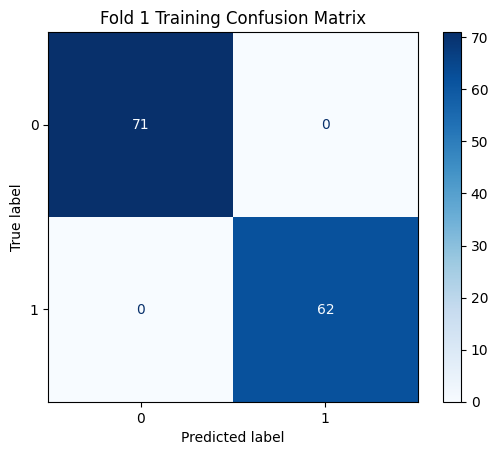

fold # 1 的最佳訓練ACC為: 1.0
fold # 1 的最佳訓練recall rate為: 1.0
fold # 1 的最佳訓練Precision為: 1.0
fold # 1 的最佳訓練F1 score為: 1.0
fold # 1 的最佳訓練TN為: 71
fold # 1 的最佳訓練FP為: 0
fold # 1 的最佳訓練FN為: 0
fold # 1 的最佳訓練TP為: 62
Start getting validating-revelant data.
[[243   0]
 [  0 290]]


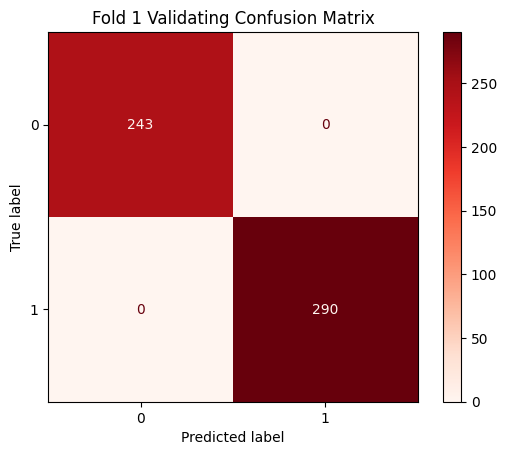

fold # 1 的驗證ACC為: 1.0
fold # 1 的驗證recall rate為: 1.0
fold # 1 的驗證Precision為: 1.0
fold # 1 的驗證F1 score為: 1.0
fold # 1 的驗證TN為: 243
fold # 1 的驗證FP為: 0
fold # 1 的驗證FN為: 0
fold # 1 的驗證TP為: 290

Processing fold # 2
Model build and compile successfully!!
Start getting training-revelant data.
[[62  0]
 [ 0 71]]


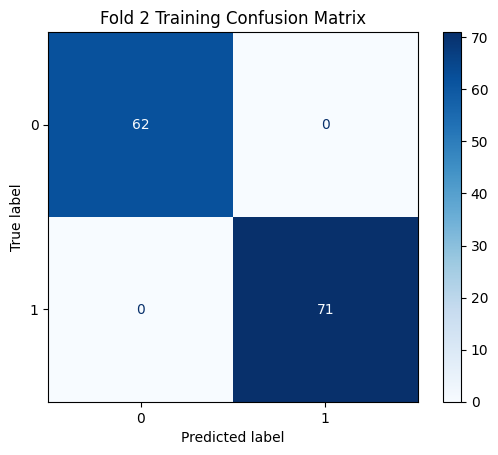

fold # 2 的最佳訓練ACC為: 1.0
fold # 2 的最佳訓練recall rate為: 1.0
fold # 2 的最佳訓練Precision為: 1.0
fold # 2 的最佳訓練F1 score為: 1.0
fold # 2 的最佳訓練TN為: 62
fold # 2 的最佳訓練FP為: 0
fold # 2 的最佳訓練FN為: 0
fold # 2 的最佳訓練TP為: 71
Start getting validating-revelant data.
[[249   3]
 [  2 279]]


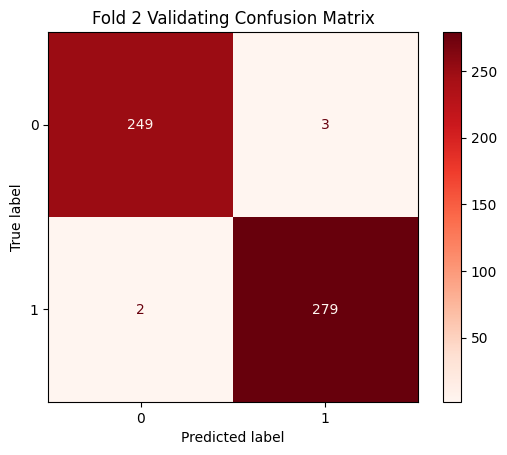

fold # 2 的驗證ACC為: 0.9906191229820251
fold # 2 的驗證recall rate為: 0.9906191229820251
fold # 2 的驗證Precision為: 0.9893617021276596
fold # 2 的驗證F1 score為: 0.9899900132814795
fold # 2 的驗證TN為: 249
fold # 2 的驗證FP為: 3
fold # 2 的驗證FN為: 2
fold # 2 的驗證TP為: 279

Processing fold # 3
Model build and compile successfully!!
Start getting training-revelant data.
[[63  0]
 [ 0 70]]


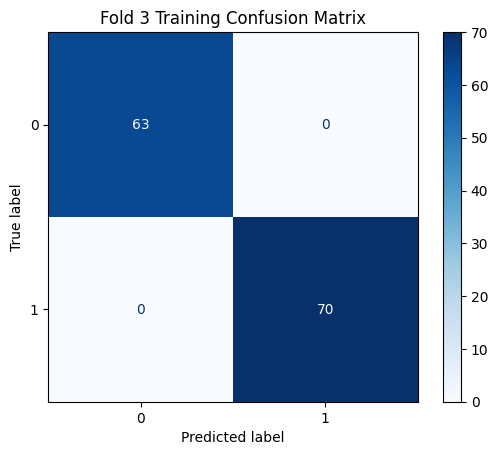

fold # 3 的最佳訓練ACC為: 1.0
fold # 3 的最佳訓練recall rate為: 1.0
fold # 3 的最佳訓練Precision為: 1.0
fold # 3 的最佳訓練F1 score為: 1.0
fold # 3 的最佳訓練TN為: 63
fold # 3 的最佳訓練FP為: 0
fold # 3 的最佳訓練FN為: 0
fold # 3 的最佳訓練TP為: 70
Start getting validating-revelant data.
[[251   0]
 [  0 282]]


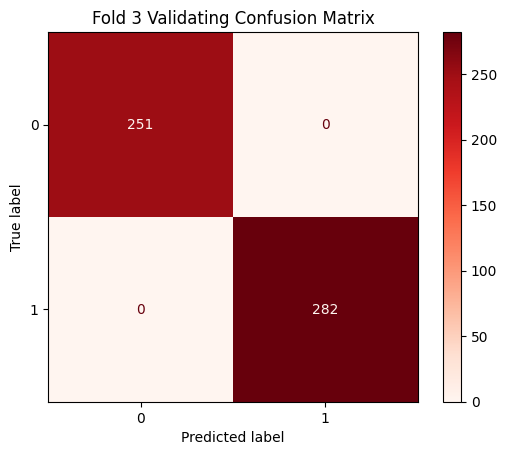

fold # 3 的驗證ACC為: 1.0
fold # 3 的驗證recall rate為: 1.0
fold # 3 的驗證Precision為: 1.0
fold # 3 的驗證F1 score為: 1.0
fold # 3 的驗證TN為: 251
fold # 3 的驗證FP為: 0
fold # 3 的驗證FN為: 0
fold # 3 的驗證TP為: 282

Processing fold # 4
Model build and compile successfully!!
Start getting training-revelant data.
[[59  0]
 [ 0 74]]


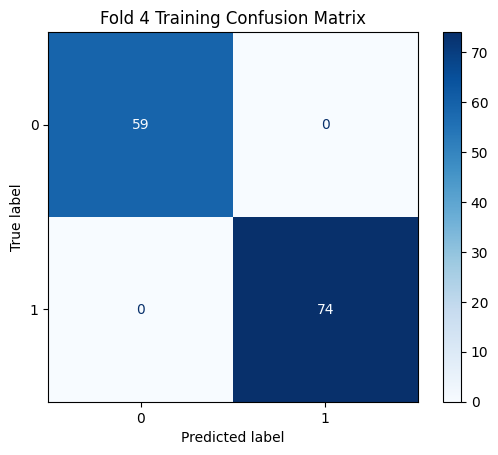

fold # 4 的最佳訓練ACC為: 1.0
fold # 4 的最佳訓練recall rate為: 1.0
fold # 4 的最佳訓練Precision為: 1.0
fold # 4 的最佳訓練F1 score為: 1.0
fold # 4 的最佳訓練TN為: 59
fold # 4 的最佳訓練FP為: 0
fold # 4 的最佳訓練FN為: 0
fold # 4 的最佳訓練TP為: 74
Start getting validating-revelant data.
[[255   0]
 [  0 278]]


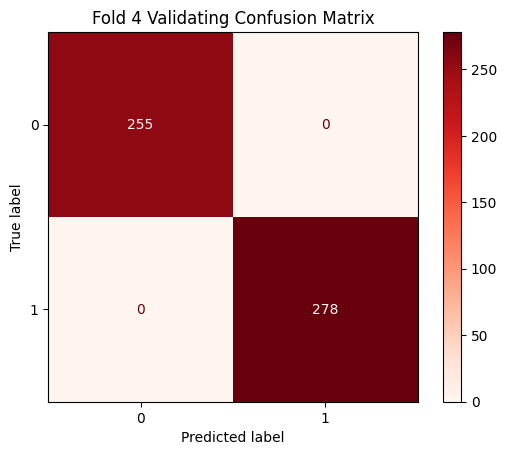

fold # 4 的驗證ACC為: 1.0
fold # 4 的驗證recall rate為: 1.0
fold # 4 的驗證Precision為: 1.0
fold # 4 的驗證F1 score為: 1.0
fold # 4 的驗證TN為: 255
fold # 4 的驗證FP為: 0
fold # 4 的驗證FN為: 0
fold # 4 的驗證TP為: 278

Processing fold # 5
Model build and compile successfully!!
Start getting training-revelant data.
[[59  0]
 [ 0 74]]


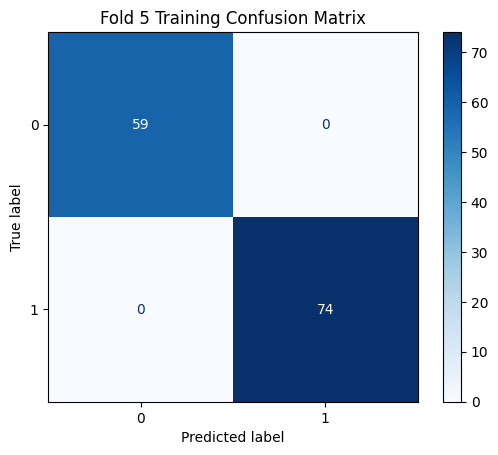

fold # 5 的最佳訓練ACC為: 1.0
fold # 5 的最佳訓練recall rate為: 1.0
fold # 5 的最佳訓練Precision為: 1.0
fold # 5 的最佳訓練F1 score為: 1.0
fold # 5 的最佳訓練TN為: 59
fold # 5 的最佳訓練FP為: 0
fold # 5 的最佳訓練FN為: 0
fold # 5 的最佳訓練TP為: 74
Start getting validating-revelant data.
[[255   0]
 [  0 278]]


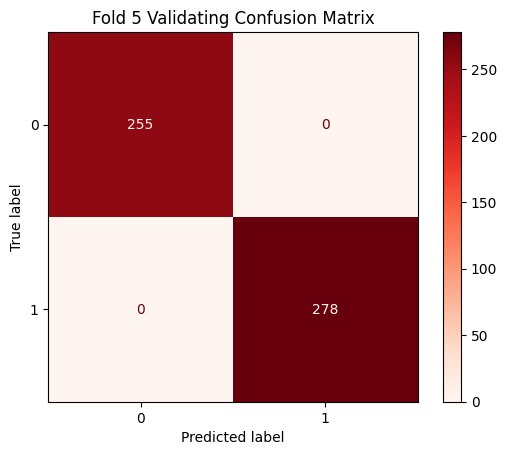

fold # 5 的驗證ACC為: 1.0
fold # 5 的驗證recall rate為: 1.0
fold # 5 的驗證Precision為: 1.0
fold # 5 的驗證F1 score為: 1.0
fold # 5 的驗證TN為: 255
fold # 5 的驗證FP為: 0
fold # 5 的驗證FN為: 0
fold # 5 的驗證TP為: 278


The Average Result of 10-cross fold validation are shown below:
Valid_ACC_average: 0.998123824596405
Valid_Precision_average: 0.997872340425532
Valid_Recall_average: 0.998123824596405
Valid_F1score_average: 0.9979980026562959


In [15]:
#此Cell是專門用來紀錄訓練和驗證時的混淆矩陣，藉此計算Percision Rate和F1-score等

#import 必要的套件
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 再次透過 K-fold cross validation 取得每個fold的資料
data = padded #準備好所有data
cate_labels = np.array( to_categorical( labels ) ) #準備好所有label

k = 5 #進行K折交叉驗證。e.g. K = 5 即為進行 5-fold cross validation、K = 10 即為進行 10-fold cross validation
num_val_samples = len( data ) // k #計算驗證集的樣本數

Valid_ACC_average = 0.0 #計算10-fold cross validation的平均驗證ACC
Valid_Precision_average = 0.0 #計算10-fold cross validation的平均驗證Precision
Valid_Recall_average = 0.0 #計算10-fold cross validation的平均驗證Recall
Valid_F1score_average = 0.0 #計算10-fold cross validation的平均驗證F1 score

#開始進行 K-fold cross validation
for i in range(k):
    print( 'Processing fold #', i + 1 )

    #準備此回合的訓練資料: 訓練資料來自第i個區塊
    training_data = data[ i * num_val_samples : ( i + 1 ) * num_val_samples ]
    training_labels = cate_labels[ i * num_val_samples : ( i + 1 ) * num_val_samples ]

    #準備此回合的驗證資料: 訓練資料來自第i個區塊
    valid_data = np.concatenate(
        [data[ : i * num_val_samples ],
         data[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    valid_labels = np.concatenate(
        [cate_labels[ : i * num_val_samples ],
         cate_labels[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    #針對這回合的訓練及驗證資料進行masking
    training_attention_mask = np.where( training_data != 0, 1, 0 )
    valid_attention_mask = np.where( valid_data != 0, 1, 0 )

    #重新建構Keras模型(已編譯過)
    model = build_model()

    #載入之前於本回合訓練時表現最佳的模型
    model_path = './BestModel_TinyBERT_BiLSTM_fold_' + str(i+1) + ".keras"

    model = keras.models.load_model (
        model_path,
        custom_objects = { "TFBertModel": ppb.TFBertModel }
    )

    #開始取得本回合的訓練相關數據
    print( 'Start getting training-revelant data.' )

    #重新跑一次模型以取得所需的數據
    training_history = model.evaluate( [ training_data, training_attention_mask ], training_labels, batch_size = batchSize, verbose = 0 ) #valid_history = [loss, acc, recall]
    training_predictions = model.predict( [ training_data, training_attention_mask ], batch_size = batchSize, verbose = 0 )

    #把二維的預測結果跟label轉換回一維的
    y_true = np.argmax( training_labels, axis = 1 )
    y_pred = np.argmax( training_predictions, axis = 1 )

    #取得並列印confusion matrix
    cm = confusion_matrix( y_true, y_pred, labels = [ 0, 1 ] ) #取得confusion matrix
    print( cm ) #把文字版confusion matrix列印出來

    #以下程式碼為把圖形版confusion matrix列印出來
    disp = ConfusionMatrixDisplay( confusion_matrix = cm, display_labels = [ 0, 1 ] )
    disp.plot( cmap = 'Blues' )
    plt.title( "Fold " + str( i + 1 ) + " Training Confusion Matrix" )
    plt.show()
    #以上程式碼為把圖形版confusion matrix列印出來

    #取得TP、TN、FP、FN
    ACC = training_history[1]
    Recall = training_history[2]
    TN, FP, FN, TP = confusion_matrix( y_true, y_pred ).ravel().tolist()
    Precision = TP / ( TP + FP )
    F1_score = 2 * ( ( Precision * Recall ) / ( Precision + Recall ) )

    #列印結果
    print( 'fold #', i + 1, '的最佳訓練ACC為:', ACC )
    print( 'fold #', i + 1, '的最佳訓練recall rate為:', Recall )
    print( 'fold #', i + 1, '的最佳訓練Precision為:', Precision )
    print( 'fold #', i + 1, '的最佳訓練F1 score為:', F1_score )
    print( 'fold #', i + 1, '的最佳訓練TN為:', TN )
    print( 'fold #', i + 1, '的最佳訓練FP為:', FP )
    print( 'fold #', i + 1, '的最佳訓練FN為:', FN )
    print( 'fold #', i + 1, '的最佳訓練TP為:', TP )

    #開始取得本回合的驗證相關數據
    print( 'Start getting validating-revelant data.' )

    #重新跑一次模型以取得所需的數據
    valid_history = model.evaluate( [ valid_data, valid_attention_mask ], valid_labels, batch_size = batchSize, verbose = 0 ) #valid_history = [loss, acc, recall]
    valid_predictions = model.predict( [ valid_data, valid_attention_mask ], batch_size = batchSize, verbose = 0 )

    #把二維的預測結果跟label轉換回一維的
    y_true = np.argmax( valid_labels, axis = 1 )
    y_pred = np.argmax( valid_predictions, axis = 1 )

    #取得並列印confusion matrix
    cm = confusion_matrix( y_true, y_pred, labels = [ 0, 1 ] ) #取得confusion matrix
    print( cm ) #把文字版confusion matrix列印出來

    #以下程式碼為把圖形版confusion matrix列印出來
    disp = ConfusionMatrixDisplay( confusion_matrix = cm, display_labels = [ 0, 1 ] )
    disp.plot( cmap = 'Reds' )
    plt.title( "Fold " + str( i + 1 ) + " Validating Confusion Matrix" )
    plt.show()
    #以上程式碼為把圖形版confusion matrix列印出來

    #取得TP、TN、FP、FN
    ACC = valid_history[1]
    Recall = valid_history[2]
    TN, FP, FN, TP = confusion_matrix( y_true, y_pred ).ravel().tolist()
    Precision = TP / ( TP + FP )
    F1_score = 2 * ( ( Precision * Recall ) / ( Precision + Recall ) )

    #列印結果並統計實驗數據
    print( 'fold #', i + 1, '的驗證ACC為:', ACC  )
    print( 'fold #', i + 1, '的驗證recall rate為:', Recall )
    print( 'fold #', i + 1, '的驗證Precision為:', Precision )
    print( 'fold #', i + 1, '的驗證F1 score為:', F1_score )
    print( 'fold #', i + 1, '的驗證TN為:', TN )
    print( 'fold #', i + 1, '的驗證FP為:', FP )
    print( 'fold #', i + 1, '的驗證FN為:', FN )
    print( 'fold #', i + 1, '的驗證TP為:', TP )
    print()
    Valid_ACC_average = Valid_ACC_average + ACC
    Valid_Precision_average = Valid_Precision_average + Precision
    Valid_Recall_average = Valid_Recall_average + Recall
    Valid_F1score_average = Valid_F1score_average + F1_score

#統計最終結果
Valid_ACC_average = Valid_ACC_average / k
Valid_Precision_average = Valid_Precision_average / k
Valid_Recall_average = Valid_Recall_average / k
Valid_F1score_average = Valid_F1score_average / k
print()
print( 'The Average Result of 10-cross fold validation are shown below:' )
print( 'Valid_ACC_average:', Valid_ACC_average )
print( 'Valid_Precision_average:', Valid_Precision_average )
print( 'Valid_Recall_average:', Valid_Recall_average )
print( 'Valid_F1score_average:', Valid_F1score_average )

In [16]:
# K-fold cross validation(因為記憶體不足導致訓練中斷的史訓練繼續的暫時版)
'''
data = padded #準備好所有data
cate_labels = np.array( to_categorical( labels ) ) #準備好所有label

k = 10 #進行K折交叉驗證。e.g. K = 5 即為進行 5-fold cross validation、K = 10 即為進行 10-fold cross validation
num_val_samples = len( data ) // k #計算驗證集的樣本數

#開始進行 K-fold cross validation
for i in range( 8, k, 1 ):
    print( 'Processing fold #', i + 1 )

    #準備此回合的訓練資料: 訓練資料來自第i個區塊
    training_data = data[ i * num_val_samples : ( i + 1 ) * num_val_samples ]
    training_labels = cate_labels[ i * num_val_samples : ( i + 1 ) * num_val_samples ]

    #準備此回合的驗證資料: 訓練資料來自第i個區塊
    valid_data = np.concatenate(
        [data[ : i * num_val_samples ],
         data[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    valid_labels = np.concatenate(
        [cate_labels[ : i * num_val_samples ],
         cate_labels[ ( i + 1 ) * num_val_samples : ] ],
        axis = 0 )

    #針對這回合的訓練及驗證資料進行masking
    training_attention_mask = np.where( training_data != 0, 1, 0 )
    valid_attention_mask = np.where( valid_data != 0, 1, 0 )

    model = build_model() #重新建構Keras模型(已編譯過)

    #開始進行本回合的訓練

    #設定call back
    callbacksList = [
        #以下這個callback為在每個週期結束後若loss有改善，則把當下的模型給存起來
        #簡單來說這個callback的目的就是希望可以把loss最好的那個週期的模型給存起來
        keras.callbacks.ModelCheckpoint(
            filepath = "BestModel_TinyBERT_BiLSTM_fold_" + str(i+1) + ".keras", #存檔的路徑及檔名
            monitor = "loss", #當loss有改善時才會儲存模型，別忘了若寫了這一行程式碼
                              #則一定要在此callback裡面也加上save_best_only = True這一
                              #行程式碼才行
            save_best_only = True,
        )
    ]

    #開始訓練
    print( 'Start training.' )
    training_history = model.fit(
                           [ training_data, training_attention_mask ], #訓練資料，貌似需為NumPy陣列或DataSet物件
                             training_labels, #訓練資料的label，貌似需為NumPy陣列或DataSet物件
                             epochs = epoch,
                             batch_size = batchSize,
                             callbacks = callbacksList,
                       )

    #儲存部份訓練資訊
    average_acc_train = np.mean( training_history.history[ 'accuracy' ] )
    all_train_acc_mean.append( average_acc_train )
    print( 'The average acc in training phase is:', average_acc_train  )
    # average_recall_train = np.mean( training_history.history[ 'recall' ] )
    # all_train_recall_mean.append( average_recall_train )
    # print( 'The average recall in training phase is:', average_recall_train  )

    #開始進行本回合的驗證

    #載入於本回合訓練時表現最佳的模型
    model = keras.models.load_model (
        "BestModel_TinyBERT_BiLSTM_fold_" + str(i+1) + ".keras",
        custom_objects = { "TFBertModel": ppb.TFBertModel }
    )

    #開始驗證
    print( 'Start validating.' )
    valid_history = model.evaluate( [ valid_data, valid_attention_mask ], valid_labels, batch_size = batchSize ) #valid_history = [loss, acc, recall]
    all_valid_acc.append( valid_history[1] )
    all_valid_recall.append( valid_history[2] )
'''

'\ndata = padded #準備好所有data\ncate_labels = np.array( to_categorical( labels ) ) #準備好所有label\n\nk = 10 #進行K折交叉驗證。e.g. K = 5 即為進行 5-fold cross validation、K = 10 即為進行 10-fold cross validation\nnum_val_samples = len( data ) // k #計算驗證集的樣本數\n\n#開始進行 K-fold cross validation\nfor i in range( 8, k, 1 ):\n    print( \'Processing fold #\', i + 1 )\n\n    #準備此回合的訓練資料: 訓練資料來自第i個區塊\n    training_data = data[ i * num_val_samples : ( i + 1 ) * num_val_samples ]\n    training_labels = cate_labels[ i * num_val_samples : ( i + 1 ) * num_val_samples ]\n\n    #準備此回合的驗證資料: 訓練資料來自第i個區塊\n    valid_data = np.concatenate(\n        [data[ : i * num_val_samples ],\n         data[ ( i + 1 ) * num_val_samples : ] ],\n        axis = 0 )\n\n    valid_labels = np.concatenate(\n        [cate_labels[ : i * num_val_samples ],\n         cate_labels[ ( i + 1 ) * num_val_samples : ] ],\n        axis = 0 )\n\n    #針對這回合的訓練及驗證資料進行masking\n    training_attention_mask = np.where( training_data != 0, 1, 0 )\n    valid_attention

In [17]:
#Debug用
print( all_valid_acc )
print( all_valid_recall )
print( np.mean( all_valid_acc ) )
print( np.mean( all_valid_recall ) )

[1.0, 0.9906191229820251, 1.0, 1.0, 1.0]
[1.0, 0.9906191229820251, 1.0, 1.0, 1.0]
0.998123824596405
0.998123824596405


In [18]:
# Plot training and validating accuracy and loss curve
h = training_history.history
epochs = range( len ( h['loss'] ) )

plt.figure( figsize = ( 20, 5 ) )
ax = plt.subplot( 1, 2, 1 )
ax.set_title( 'Train and Valid Accuracy' )
plt.plot( epochs, h['accuracy'], 'b', label='Train accuracy' )
plt.plot( epochs, h['val_accuracy'], 'r', label='Valid accuracy' )
plt.legend()

ax = plt.subplot(1, 2, 2)
ax.set_title('Train and Valid Loss')
plt.plot(epochs, h['loss'], 'b', label='Train loss')
plt.plot(epochs, h['val_loss'], 'r', label='Valid loss')
plt.legend()

plt.savefig(f'Train_Valid_ACCandLOSS_Tiny_BERT.png')

plt.show()

AttributeError: 'list' object has no attribute 'history'

In [ ]:
# Plot training and validating recall curve
h = history.history
epochs = range( len ( h['loss'] ) )

plt.figure( figsize = ( 20, 5 ) )
ax = plt.subplot( 1, 2, 1 )
ax.set_title( 'Train and Valid Recall Rate' )
plt.plot( epochs, h['recall'], 'b', label='Train recall rate' )
plt.plot( epochs, h['val_recall'], 'r', label='Valid recall rate' )
plt.legend()

plt.savefig(f'Train_Valid_Recall_Tiny_BERT.png')

plt.show()

以下為TSET

In [24]:
# ===== TEST CONFIG =====

# 你要測哪一個檔案就改這裡
TEST_PATH = "./TestingData/xss_encoded_dataset_test.csv"
# 例如：
# TEST_PATH = "./TestingData/raw_test.csv"
# TEST_PATH = "./TestingData/single_encoded_test.csv"
# TEST_PATH = "./TestingData/double_encoded_test.csv"

# 固定使用同一個 fold 模型做比較
MODEL_PATH = "./BestModel_TinyBERT_BiLSTM_fold_5.keras"

print("TEST_PATH :", TEST_PATH)
print("MODEL_PATH:", MODEL_PATH)
print("maxLen    :", maxLen)
print("batchSize :", batchSize)

TEST_PATH : ./TestingData/xss_encoded_dataset_test.csv
MODEL_PATH: ./BestModel_TinyBERT_BiLSTM_fold_5.keras
maxLen    : 600
batchSize : 32


In [25]:
# ===== LOAD TEST CSV =====

import os
import pandas as pd
import numpy as np

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(f"找不到測試檔案: {TEST_PATH}")

df_test = pd.read_csv(TEST_PATH)

print("df_test.shape =", df_test.shape)
print("Columns =", list(df_test.columns))
display(df_test.head())

# 自動找 payload / label 欄位
if "payload" in df_test.columns:
    payload_col = "payload"
else:
    payload_col = df_test.columns[0]

if "label" in df_test.columns:
    label_col = "label"
else:
    if len(df_test.columns) < 2:
        raise ValueError("測試檔至少要有兩欄：payload 與 label")
    label_col = df_test.columns[1]

print("payload_col =", payload_col)
print("label_col   =", label_col)

df_test[payload_col] = df_test[payload_col].astype(str)
df_test[label_col] = df_test[label_col].astype(int)

print("Total samples:", len(df_test))
print("Label distribution:")
print(df_test[label_col].value_counts(dropna=False))

df_test.shape = (664, 3)
Columns = ["<object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>", '1', 'raw']


,"<object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>",1,raw
0,</span>. <i>Behavioral and Brain Sciences </i>...,0,raw
1,%253Cdetails%2520open%2520ontoggle%253D%2522se...,1,double_encoded
2,"<li>if a move ""forks"" to create two threats at...",0,raw
3,"<svg onload=""const f=window['al'+'ert'];f(1)"">...",1,raw
4,"<sup id=""cite_ref-Roberts_147-0"" class=""refere...",0,raw


payload_col = <object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>
label_col   = 1
Total samples: 664
Label distribution:
1
0    337
1    327
Name: count, dtype: int64


In [26]:
# ===== TOKENIZATION =====

test_tokenized = df_test[payload_col].apply(
    lambda x: tokenizer.encode(
        x,
        add_special_tokens=True,
        truncation=True,
        max_length=600
    )
)

print("第一筆 tokenized 長度:", len(test_tokenized.iloc[0]))
print("第一筆原始 payload:")
print(df_test[payload_col].iloc[0])
print("\n第一筆 decode 後 token:")
print(tokenizer.decode(test_tokenized.iloc[0]))

第一筆 tokenized 長度: 415
第一筆原始 payload:
</span>. <i>Behavioral and Brain Sciences </i>. <b>3 </b> (3): 417–457. <a href="/wiki/Digital_object_identifier" title="Digital object identifier">doi </a>:<a rel="nofollow" class="external text" href="https://doi.org/10.1017%2FS0140525X00005756">10.1017/S0140525X00005756 </a>. </cite><span title="ctx_ver=Z39.88-2004&amp;rft_val_fmt=info%3Aofi%2Ffmt%3Akev%3Amtx%3Ajournal&amp;rft.genre=article&amp;rft.jtitle=Behavioral+and+Brain+Sciences&amp;rft.atitle=Minds%2C+Brains+and+Programs&amp;rft.volume=3&amp;rft.issue=3&amp;rft.pages=417-457&amp;rft.date=1980&amp;rft_id=info%3Adoi%2F10.1017%2FS0140525X00005756&amp;rft.aulast=Searle&amp;rft.aufirst=John&amp;rft_id=http%3A%2F%2Fcogprints.org%2F7150%2F1%2F10.1.1.83.5248.pdf&amp;rfr_id=info%3Asid%2Fen.wikipedia.org%3AArtificial+intelligence" class="Z3988">

第一筆 decode 後 token:
[CLS] < / span >. < i > behavioral and brain sciences < / i >. < b > 3 < / b > ( 3 ) : 417 – 457. < a href = " / wiki / digital _ objec

In [27]:
# ===== PADDING + MASK =====

test_padded = []
test_labels = []

for idx in range(len(test_tokenized)):
    token = test_tokenized.iloc[idx].copy()
    label = int(df_test[label_col].iloc[idx])

    if len(token) < maxLen:
        token = token + [0] * (maxLen - len(token))
    else:
        token = token[:maxLen]

    test_padded.append(token)
    test_labels.append(label)

test_data = np.array(test_padded, dtype=np.int32)
test_labels = np.array(test_labels, dtype=np.int32)
test_labels_cat = tf.keras.utils.to_categorical(test_labels, num_classes=2)

test_attention_mask = np.where(test_data != 0, 1, 0)

print("test_data shape          :", test_data.shape)
print("test_labels shape        :", test_labels.shape)
print("test_labels_cat shape    :", test_labels_cat.shape)
print("test_attention_mask shape:", test_attention_mask.shape)

test_data shape          : (664, 600)
test_labels shape        : (664,)
test_labels_cat shape    : (664, 2)
test_attention_mask shape: (664, 600)


In [28]:
# ===== LOAD MODEL =====

import os
from tensorflow import keras

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"找不到模型檔案: {MODEL_PATH}")

model = keras.models.load_model(
    MODEL_PATH,
    custom_objects={"TFBertModel": ppb.TFBertModel}
)

print("模型載入成功")
model.summary()

模型載入成功
Model: "model_5"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_ids (InputLayer)         [(None, None)]       0           []                               
                                                                                                  
 attention_mask (InputLayer)    [(None, None)]       0           []                               
                                                                                                  
 tf_bert_model_11 (TFBertModel)  TFBaseModelOutputWi  4385920    ['input_ids[0][0]',              
                                thPoolingAndCrossAt               'attention_mask[0][0]']         
                                tentions(last_hidde                                               
                                n_state=(None, None                                  

In [29]:
# ===== EVALUATE + PREDICT =====

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = model.evaluate(
    [test_data, test_attention_mask],
    test_labels_cat,
    batch_size=batchSize,
    verbose=1
)

print("\nKeras metrics:")
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value}")

y_prob = model.predict(
    [test_data, test_attention_mask],
    batch_size=batchSize,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels

print("\n===== SKLEARN METRICS =====")
print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, zero_division=0))
print("F1-score :", f1_score(y_true, y_pred, zero_division=0))

cm = confusion_matrix(y_true, y_pred)

print("\n===== CONFUSION MATRIX =====")
print(cm)

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

21/21 [==============================] - 3s 90ms/step - loss: 0.0032 - accuracy: 1.0000 - recall_4: 1.0000

Keras metrics:
loss: 0.0032460219226777554
accuracy: 1.0
recall_4: 1.0
21/21 [==============================] - 3s 89ms/step

===== SKLEARN METRICS =====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

===== CONFUSION MATRIX =====
[[337   0]
 [  0 327]]

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       337
           1     1.0000    1.0000    1.0000       327

    accuracy                         1.0000       664
   macro avg     1.0000    1.0000    1.0000       664
weighted avg     1.0000    1.0000    1.0000       664



In [30]:
# ===== SAVE PREDICTION RESULTS =====

df_result = df_test.copy()
df_result["pred"] = y_pred
df_result["correct"] = (df_result[label_col] == df_result["pred"]).astype(int)
df_result["prob_benign"] = y_prob[:, 0]
df_result["prob_malicious"] = y_prob[:, 1]

result_path = "test_predictions_result.csv"
error_path = "test_misclassified_only.csv"

df_result.to_csv(result_path, index=False, encoding="utf-8-sig")

df_errors = df_result[df_result["correct"] == 0].copy()
df_errors.to_csv(error_path, index=False, encoding="utf-8-sig")

print("全部測試結果已儲存到:", result_path)
print("誤判樣本已儲存到    :", error_path)
print("誤判筆數:", len(df_errors))

display(df_errors.head(20))

全部測試結果已儲存到: test_predictions_result.csv
誤判樣本已儲存到    : test_misclassified_only.csv
誤判筆數: 0


,"<object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>",1,raw,pred,correct,prob_benign,prob_malicious


In [31]:
# ===== ANALYZE FALSE NEGATIVES / FALSE POSITIVES =====

false_negatives = df_result[(df_result[label_col] == 1) & (df_result["pred"] == 0)].copy()
false_positives = df_result[(df_result[label_col] == 0) & (df_result["pred"] == 1)].copy()

print("False Negatives (惡意但被判成正常):", len(false_negatives))
print("False Positives (正常但被判成惡意):", len(false_positives))

print("\n--- False Negatives sample ---")
display(false_negatives.head(10))

print("\n--- False Positives sample ---")
display(false_positives.head(10))

False Negatives (惡意但被判成正常): 0
False Positives (正常但被判成惡意): 0

--- False Negatives sample ---


,"<object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>",1,raw,pred,correct,prob_benign,prob_malicious



--- False Positives sample ---


,"<object data='data:text/html,<img src=x onerror=window[%27al%27+%27ert%27](1)>'></object>",1,raw,pred,correct,prob_benign,prob_malicious


以下是轉換檔案

In [ ]:
import pandas as pd

# 讀檔
with open("decode.txt", "r", encoding="utf-8") as f:
    decode_lines = [line.strip() for line in f if line.strip()]

with open("encode.txt", "r", encoding="utf-8") as f:
    encode_lines = [line.strip() for line in f if line.strip()]

with open("benign.txt", "r", encoding="utf-8") as f:
    bengin_lines = [line.strip() for line in f if line.strip()]

# 建 dataframe
data = []

# bengin
for p in bengin_lines:
    data.append({
        "payload": p,
        "label": 0,
        "type": "raw"
    })

# 原始 payload
for p in decode_lines:
    data.append({
        "payload": p,
        "label": 1,
        "type": "raw"
    })

# 雙層編碼 payload
for p in encode_lines:
    data.append({
        "payload": p,
        "label": 1,
        "type": "double_encoded"
    })

df = pd.DataFrame(data)

# 存 CSV
df.to_csv("xss_encoded_dataset.csv", index=False, encoding="utf-8")

print("✅ CSV 產生完成！")
print(df.head())

In [ ]:
import os
import random

# 設定輸入與輸出檔名
input_file = 'xss_encoded_dataset.csv'
output_a = 'xss_encoded_dataset_test.csv'
output_b = 'xss_encoded_dataset_train.csv'

def split_and_shuffle_no_label(file_path):
    if not os.path.exists(file_path):
        print(f"錯誤：找不到檔案 {file_path}")
        return

    with open(file_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    if not lines:
        print("檔案是空的！")
        return

    # --- 修改重點：直接跳過第一行，只取後面的資料 ---
    data_lines = lines[1:]

    # 加入隨機打亂功能
    random.shuffle(data_lines)
    # ------------------------------------------

    # 決定拆分點 (這裡設定為 1:1 拆分，你可以自行調整比例)
    mid = len(data_lines) // 2

    with open(output_a, 'w', encoding='utf-8') as fa, \
         open(output_b, 'w', encoding='utf-8') as fb:
        
        # 直接寫入打亂後的資料，不寫入 header
        for i, line in enumerate(data_lines):
            if i < mid:
                fa.write(line)
            else:
                fb.write(line)
                
    print(f"處理完成！已剔除標題列並完成隨機打亂。")
    print(f"檔案 A (Test) 筆數: {mid}")
    print(f"檔案 B (Train) 筆數: {len(data_lines) - mid}")

# 執行函式
split_and_shuffle_no_label(input_file)